# MNIST Classification with Artificial Neural Network (ANN) and Support Vector Machine (SVM)

## About the MNIST Dataset

**MNIST** (Modified National Institute of Standards and Technology) is a collection of 70,000 grayscale images of handwritten digits (0–9), each 28×28 pixels. It is split into 60,000 training images and 10,000 test images.

### History
- The digits come from two NIST databases: Special Database 3 (written by US Census Bureau employees) and Special Database 1 (written by American high-school students).
- In the 1990s, Yann LeCun, Corinna Cortes, and Christopher Burges "modified" the NIST data: they re-mixed the two sources so the training and test sets were more representative, normalized each digit to fit a 20×20 box, and centered it in a 28×28 image.
- It was released alongside LeCun's work on convolutional neural networks (LeNet-5), which was used for reading handwritten digits on bank cheques and postal codes.

### Importance in AI
- It became the standard benchmark for comparing machine learning algorithms (k-NN, SVM, ANN, CNN, and more) on a common, fair footing.
- It played a role in the rise of deep learning: LeNet-5 showed that neural networks trained with backpropagation could solve a real-world vision task.
- It is small, clean, and well-labeled, so researchers and students could experiment without large compute or heavy preprocessing. This earned it the nickname "the *Hello World* of machine learning."

### Why It Is Still Relevant
- **Education:** It is the common first project for learning classification, neural networks, and ML frameworks.
- **Quick prototyping:** It trains in seconds to minutes on a laptop, which makes it good for sanity-checking new ideas, architectures, and code.
- **Method comparison:** It is a simple setting for comparing classical models (such as SVM) with neural networks, which is what this notebook does.
- **Known limitations:** Modern models score above 99% on MNIST, so it no longer separates state-of-the-art methods. Harder successors such as Fashion-MNIST, EMNIST, and CIFAR-10 are used for that.

## Artificial Neural Network (ANN)

In the first section of this notebook, we want to explore how ANN could classify the hand-written digits in MNIST dataset quite reliably, even with relatively simple network architecture


In [1]:
from typing import List

In [2]:
import tensorflow as tf

# List available hardware
devices: List = tf.config.list_physical_devices()
print(f"List CPU and GPU available: {devices}")

List CPU and GPU available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


Fortunately, Keras / Tensorflow already have MNIST bundled with the library. So, we will use that here

In [3]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

Now, let's see how MNIST dataset looks like.

So that we have an idea what kind of dataset we are working with

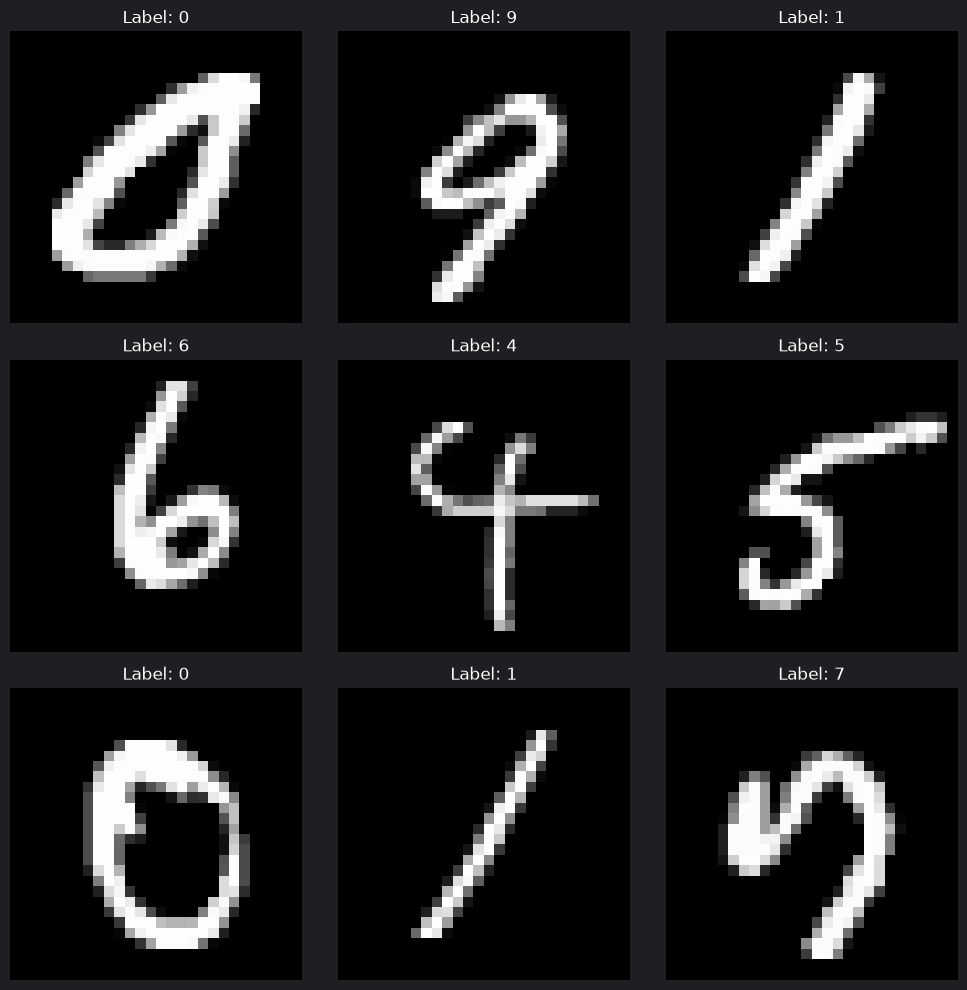

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
idx = rng.choice(
    len(X_test),
    size=10,
    replace=False,
)

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))

for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Build the Neural Network

Network design:
- **Input:** 28×28 image flattened into 784 values, with pixels scaled to the 0–1 range
- **Hidden layers:** two dense layers (128 and 64 nodes) with ReLU activation
- **Output:** 10 nodes (one per digit) with SoftMax activation, giving a probability for each digit
- **Loss:** cross-entropy over the 10 classes. Our labels are integers (0–9), so we use `sparse_categorical_crossentropy`, which is the same as categorical cross-entropy without one-hot encoding the labels
- **Optimizer:** Adam

In [5]:
from tensorflow import keras
from tensorflow.keras import layers

# Scale pixel values from 0-255 to 0-1
X_train_scaled = X_train.astype("float32") / 255.0
X_test_scaled = X_test.astype("float32") / 255.0

model = keras.Sequential(
    [
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128,
)

test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.4f}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8994 - loss: 0.3556 - val_accuracy: 0.9625 - val_loss: 0.1426
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9581 - loss: 0.1446 - val_accuracy: 0.9713 - val_loss: 0.1090
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9712 - loss: 0.0984 - val_accuracy: 0.9727 - val_loss: 0.0975
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9787 - loss: 0.0733 - val_accuracy: 0.9740 - val_loss: 0.0914
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9840 - loss: 0.0568 - val_accuracy: 0.9755 - val_loss: 0.0922
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9874 - loss: 0.0449 - val_accuracy: 0.9755 - val_loss: 0.0924
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9901 - loss: 0.0360 - val_accuracy: 0.9743 - val_loss: 0.0940
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9922 - loss: 0.0298 - val_accuracy: 0.

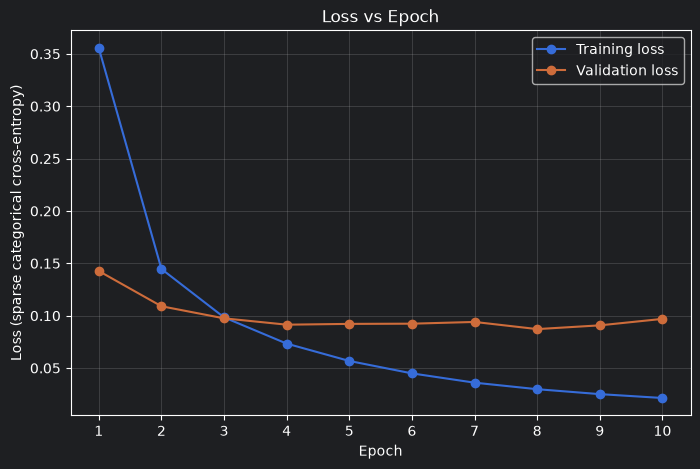

In [7]:
epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (sparse categorical cross-entropy)")
plt.title("Loss vs Epoch")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

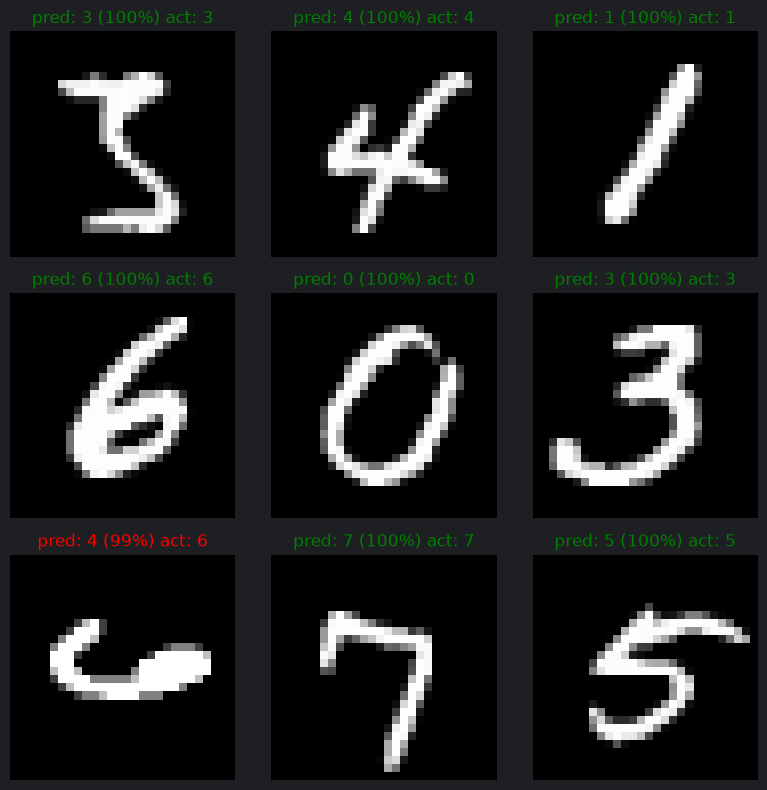

In [8]:
# Random inference on unseen test images
rng = np.random.default_rng()
idx = rng.choice(len(X_test_scaled), size=9, replace=False)

probs = model.predict(X_test_scaled[idx], verbose=0)
preds = probs.argmax(axis=1)

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(8, 8))
for ax, i, pred, p in zip(axes.ravel(), idx, preds, probs):
    actual = y_test[i]
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(
        f"pred: {pred} ({p[pred]:.0%}) act: {actual}",
        color="green" if pred == actual else "red",
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

## Support Vector Machine (SVM)

In the second section, we classify the same MNIST digits with an SVM using the RBF (non-linear) kernel.

SVM training time grows quickly with the number of samples (roughly quadratic), so we train on a 10,000-image subset of the training set to keep it fast. We still evaluate on the full 10,000-image test set. Increase `N_TRAIN` to use more data, at the cost of longer training.

In [9]:
import time

from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC

N_TRAIN = 10_000

# SVM expects flat 2D input: (samples, 784 features)
X_train_flat = X_train_scaled.reshape(len(X_train_scaled), -1)
X_test_flat = X_test_scaled.reshape(len(X_test_scaled), -1)

# Random subset of the training data
subset_idx = np.random.default_rng(42).choice(len(X_train_flat), size=N_TRAIN, replace=False)

svm = SVC(kernel="rbf", C=5, gamma="scale")

start = time.perf_counter()
svm.fit(X_train_flat[subset_idx], y_train[subset_idx])
print(f"Training time: {time.perf_counter() - start:.1f}s")

y_pred = svm.predict(X_test_flat)
print(f"SVM test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, digits=4))

Training time: 7.7s
SVM test accuracy: 0.9688
              precision    recall  f1-score   support

           0     0.9700    0.9898    0.9798       980
           1     0.9834    0.9903    0.9868      1135
           2     0.9635    0.9709    0.9672      1032
           3     0.9540    0.9653    0.9596      1010
           4     0.9688    0.9796    0.9742       982
           5     0.9735    0.9473    0.9602       892
           6     0.9679    0.9770    0.9725       958
           7     0.9724    0.9591    0.9657      1028
           8     0.9649    0.9600    0.9624       974
           9     0.9685    0.9445    0.9563      1009

    accuracy                         0.9688     10000
   macro avg     0.9687    0.9684    0.9685     10000
weighted avg     0.9688    0.9688    0.9688     10000



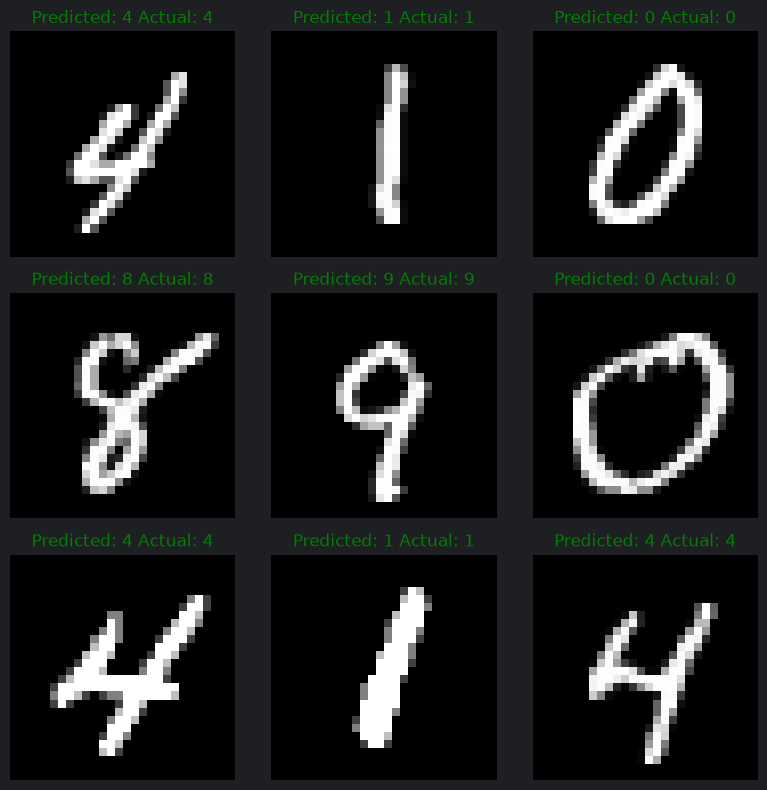

In [10]:
# Random inference on unseen test images
rng = np.random.default_rng()
idx = rng.choice(len(X_test_flat), size=9, replace=False)

preds = svm.predict(X_test_flat[idx])

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(8, 8))
for ax, i, pred in zip(axes.ravel(), idx, preds):
    actual = y_test[i]
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(
        f"Predicted: {pred} Actual: {actual}",
        color="green" if pred == actual else "red",
    )
    ax.axis("off")
plt.tight_layout()
plt.show()